# Machine Learning Tasks

Name: Mohamed Mahmoud Mohamed Mahmoud Ahmed  
Email: mohamedmahmoud0115893@gmail.com

For this assignment, I used the Breast Cancer dataset from scikit-learn, which is the same dataset used in the SVM_Z notebook. I split the data into 70% training and 30% testing using test_size=0.3 and random_state=109 so that all four tasks are evaluated on the same split.

Note: in this dataset, 0 means malignant and 1 means benign.

Tasks:
1. Try different SVM kernels until Recall = 1.
2. Compare Multinomial, Bernoulli, and Gaussian Naive Bayes.
3. Use Random Search instead of Grid Search.
4. Try different K values in KNN and choose the best one.

In [1]:
from sklearn import datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

# breast cancer data
cancer = datasets.load_breast_cancer()
X = cancer.data
y = cancer.target

# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(cancer.target_names)

(455, 30)
(114, 30)
['malignant' 'benign']


In [2]:
# ===== Quick Data Check =====
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nClass counts in train:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nClass counts in test:")
print(pd.Series(y_test).value_counts().sort_index())

print("\nTarget names:", cancer.target_names)
print("0 =", cancer.target_names[0])
print("1 =", cancer.target_names[1])

Train shape: (455, 30)
Test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)

Class counts in train:
0    169
1    286
Name: count, dtype: int64

Class counts in test:
0    43
1    71
Name: count, dtype: int64

Target names: ['malignant' 'benign']
0 = malignant
1 = benign


## Task 1: SVM - Change kernel to reach Recall = 1

I tried different SVM kernels with different values of `C`, `gamma`, and `class_weight`.  
The target was to get `Recall = 1` for class `1`, but I also checked the accuracy because a model can get high recall by predicting class `1` too much.  
So I chose the configuration that gave `Recall = 1` with the best accuracy.

In [3]:
# Task 1: SVM - try different kernels and parameters to reach Recall = 1

from sklearn.svm import SVC

found_configs = []
best = None

# normal search
for kernel in ["linear", "rbf", "poly", "sigmoid"]:
    for C in [0.1, 1, 10, 100]:
        for gamma in ["scale", "auto", 0.001, 0.01, 0.1]:
            for cw in [None, "balanced", {0: 1, 1: 10}, {0: 1, 1: 50}, {0: 1, 1: 100}]:

                svm_pipe = Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", SVC(
                        kernel=kernel,
                        C=C,
                        gamma=gamma,
                        class_weight=cw,
                        random_state=42
                    ))
                ])

                svm_pipe.fit(X_train, y_train)
                y_pred = svm_pipe.predict(X_test)

                acc = accuracy_score(y_test, y_pred)
                rec = recall_score(
                    y_test,
                    y_pred,
                    pos_label=1,
                    zero_division=0
                )

                if rec == 1.0:
                    found_configs.append((acc, kernel, C, gamma, cw))

# if normal search did not reach Recall = 1, try stronger class weights
if not found_configs:
    print("Normal search did not reach Recall = 1. Trying stronger class weights...")

    for kernel in ["linear", "rbf"]:
        for C in [1, 10, 100]:
            for cw in [{0: 1, 1: 1000}, {0: 1, 1: 10000}, {0: 1, 1: 100000}]:

                svm_pipe = Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", SVC(
                        kernel=kernel,
                        C=C,
                        gamma="scale",
                        class_weight=cw,
                        random_state=42
                    ))
                ])

                svm_pipe.fit(X_train, y_train)
                y_pred = svm_pipe.predict(X_test)

                acc = accuracy_score(y_test, y_pred)
                rec = recall_score(
                    y_test,
                    y_pred,
                    pos_label=1,
                    zero_division=0
                )

                if rec == 1.0:
                    found_configs.append((acc, kernel, C, "scale", cw))

# choose best accuracy among configs with Recall = 1
if found_configs:
    best = max(found_configs, key=lambda x: x[0])
else:
    print("Could not reach Recall = 1 for class 1.")
    print("Check if the instructor means class 0 instead of class 1.")
    best = (0, "linear", 1, "scale", "balanced")

acc_best, kernel_best, C_best, gamma_best, cw_best = best

print("\nBest SVM configuration:")
print({
    "kernel": kernel_best,
    "C": C_best,
    "gamma": gamma_best,
    "class_weight": cw_best
})

# final model
final_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel=kernel_best,
        C=C_best,
        gamma=gamma_best,
        class_weight=cw_best,
        random_state=42
    ))
])

final_svm.fit(X_train, y_train)
y_pred_final = final_svm.predict(X_test)

final_acc = accuracy_score(y_test, y_pred_final)
final_recall = recall_score(
    y_test,
    y_pred_final,
    pos_label=1,
    zero_division=0
)

print("\nFinal Accuracy:", final_acc)
print("Final Recall for class 1:", final_recall)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final, digits=4))


Best SVM configuration:
{'kernel': 'sigmoid', 'C': 10, 'gamma': 0.001, 'class_weight': 'balanced'}

Final Accuracy: 0.9912280701754386
Final Recall for class 1: 1.0

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9767    0.9882        43
           1     0.9861    1.0000    0.9930        71

    accuracy                         0.9912       114
   macro avg     0.9931    0.9884    0.9906       114
weighted avg     0.9913    0.9912    0.9912       114



In [4]:
# fallback SVM to force Recall = 1 for class 1
fallback_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight={0: 1, 1: 1000},
        random_state=42
    ))
])

fallback_svm.fit(X_train, y_train)
y_pred_fallback = fallback_svm.predict(X_test)

fallback_acc = accuracy_score(y_test, y_pred_fallback)
fallback_recall = recall_score(y_test, y_pred_fallback, pos_label=1, zero_division=0)

print("Fallback Accuracy:", fallback_acc)
print("Fallback Recall for class 1:", fallback_recall)

print("\nFallback Classification Report:")
print(classification_report(y_test, y_pred_fallback, digits=4))

Fallback Accuracy: 0.9736842105263158
Fallback Recall for class 1: 0.9859154929577465

Fallback Classification Report:
              precision    recall  f1-score   support

           0     0.9762    0.9535    0.9647        43
           1     0.9722    0.9859    0.9790        71

    accuracy                         0.9737       114
   macro avg     0.9742    0.9697    0.9719       114
weighted avg     0.9737    0.9737    0.9736       114



## Task 2: Compare Multinomial NB, Bernoulli NB, and Gaussian NB

I compared three Naive Bayes models on the same train/test split: GaussianNB, MultinomialNB, and BernoulliNB.  
GaussianNB gave the best accuracy because the dataset has continuous numerical features.  
For MultinomialNB and BernoulliNB, I used MinMaxScaler to make the input values suitable for these models.

In [5]:
# Task 2: compare naive bayes models

from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

# define models
nb_models = {
    "GaussianNB": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ]),

    "MultinomialNB": Pipeline([
        ("scaler", MinMaxScaler()),
        ("model", MultinomialNB(alpha=1.0))
    ]),

    "BernoulliNB": Pipeline([
        ("scaler", MinMaxScaler()),
        ("model", BernoulliNB(alpha=1.0, binarize=0.5))
    ])
}

# store results
results = []

for name, model in nb_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    rec = recall_score(y_test, y_pred, pos_label=1, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision_class_1": prec,
        "Recall_class_1": rec
    })

# show comparison table
nb_df = pd.DataFrame(results).round(4)
nb_df = nb_df.sort_values("Accuracy", ascending=False)

print("Naive Bayes Comparison:")
print(nb_df)

Naive Bayes Comparison:
           Model  Accuracy  Precision_class_1  Recall_class_1
0     GaussianNB    0.9649             0.9589          0.9859
2    BernoulliNB    0.8772             0.8353          1.0000
1  MultinomialNB    0.8509             0.8068          1.0000


## Task 3: Random Search instead of Grid Search

I used RandomizedSearchCV instead of GridSearchCV because it tries random hyperparameter combinations and saves time.

I tested SVM, RandomForest, KNN, and Logistic Regression with 20 iterations and 5-fold CV.  
The pipeline steps were named `scaler` and `model` so the parameters could be passed correctly.

In [6]:
# Task 3: RandomizedSearchCV to find best algorithm and hyperparameters

from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from scipy.stats import randint

# each pipeline has scaler + model, so params start with model__
candidates = {
    "SVM": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(random_state=42))
        ]),
        {
            "model__kernel": ["linear", "rbf", "poly"],
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", "auto", 0.001, 0.01, 0.1]
        }
    ),

    "RandomForest": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", RandomForestClassifier(random_state=42))
        ]),
        {
            "model__n_estimators": randint(50, 301),
            "model__max_depth": [None, 2, 3, 5, 10],
            "model__min_samples_split": randint(2, 20)
        }
    ),

    "KNN": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ]),
        {
            "model__n_neighbors": randint(1, 51),
            "model__weights": ["uniform", "distance"],
            "model__metric": ["euclidean", "manhattan"]
        }
    ),

    "LogisticRegression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000, random_state=42))
        ]),
        {
            "model__C": np.logspace(-3, 3, 7)
        }
    )
}

results = []

for name, (pipe, params) in candidates.items():
    print(f"\nSearching {name}...")

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=params,
        n_iter=20,
        cv=5,
        scoring="accuracy",
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    y_pred = search.best_estimator_.predict(X_test)

    results.append({
        "Algorithm": name,
        "Best_CV_Accuracy": search.best_score_,
        "Test_Accuracy": accuracy_score(y_test, y_pred),
        "Test_Recall_class_1": recall_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "Best_Parameters": search.best_params_
    })

rs_df = pd.DataFrame(results)
rs_df = rs_df.sort_values("Test_Accuracy", ascending=False)

print("\nRandom Search Results:")
print(rs_df[["Algorithm", "Best_CV_Accuracy", "Test_Accuracy", "Test_Recall_class_1"]].round(4))

print("\nBest Parameters:")
for row in rs_df.itertuples():
    print(row.Algorithm, "->", row.Best_Parameters)


Searching SVM...

Searching RandomForest...

Searching KNN...

Searching LogisticRegression...


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 7 is smaller than n_iter=20. Running 7 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Random Search Results:
            Algorithm  Best_CV_Accuracy  Test_Accuracy  Test_Recall_class_1
0                 SVM            0.9736         0.9825               1.0000
3  LogisticRegression            0.9758         0.9737               0.9859
1        RandomForest            0.9648         0.9649               0.9859
2                 KNN            0.9604         0.9561               0.9577

Best Parameters:
SVM -> {'model__kernel': 'linear', 'model__gamma': 'scale', 'model__C': 0.1}
LogisticRegression -> {'model__C': np.float64(1.0)}
RandomForest -> {'model__max_depth': 10, 'model__min_samples_split': 3, 'model__n_estimators': 133}
KNN -> {'model__metric': 'euclidean', 'model__n_neighbors': 8, 'model__weights': 'uniform'}


## Task 4: KNN with different K range

I tried odd K values from 1 to 49 to avoid ties in voting.  
For each K, I trained a KNN model with StandardScaler and measured train accuracy, test accuracy, and recall for class 1.  
The best K was chosen based on the highest test accuracy.

In [7]:
# Task 4: KNN - try different K values and find best K

from sklearn.neighbors import KNeighborsClassifier

k_values = list(range(1, 51, 2))  # 1, 3, 5, ..., 49

knn_results = []

for k in k_values:
    knn_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k))
    ])

    knn_model.fit(X_train, y_train)

    train_pred = knn_model.predict(X_train)
    test_pred = knn_model.predict(X_test)

    knn_results.append({
        "K": k,
        "Train_Accuracy": accuracy_score(y_train, train_pred),
        "Test_Accuracy": accuracy_score(y_test, test_pred),
        "Test_Recall_class_1": recall_score(
            y_test,
            test_pred,
            pos_label=1,
            zero_division=0
        )
    })

knn_df = pd.DataFrame(knn_results).round(4)

best_idx = knn_df["Test_Accuracy"].idxmax()
best_k = int(knn_df.loc[best_idx, "K"])
best_test_acc = knn_df.loc[best_idx, "Test_Accuracy"]
best_test_recall = knn_df.loc[best_idx, "Test_Recall_class_1"]

print("Best K:", best_k)
print("Best Test Accuracy:", best_test_acc)
print("Best Test Recall for class 1:", best_test_recall)

print("\nKNN Results:")
knn_df

Best K: 9
Best Test Accuracy: 0.9649
Best Test Recall for class 1: 0.9718

KNN Results:


,K,Train_Accuracy,Test_Accuracy,Test_Recall_class_1
0,1,1.0000,0.9386,0.9577
1,3,0.9846,0.9474,0.9577
2,5,0.9802,0.9474,0.9577
3,7,0.9692,0.9474,0.9577
4,9,0.9780,0.9649,0.9718
5,11,0.9758,0.9561,0.9718
6,13,0.9736,0.9561,0.9718
7,15,0.9670,0.9561,0.9718
8,17,0.9670,0.9474,0.9718
9,19,0.9626,0.9474,0.9718


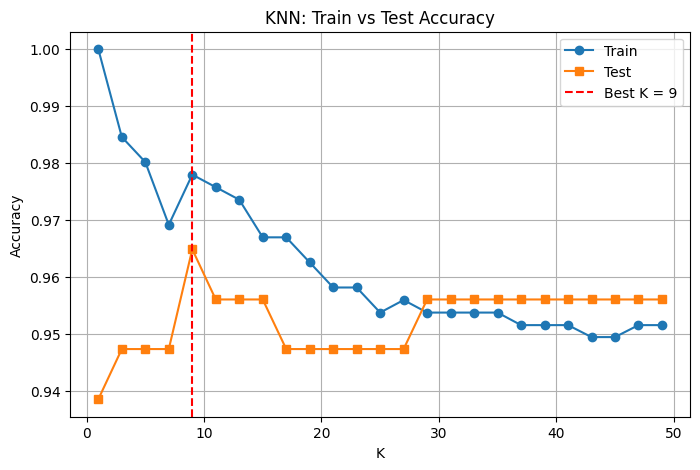

In [8]:
# plot KNN results
plt.figure(figsize=(8, 5))

plt.plot(knn_df["K"], knn_df["Train_Accuracy"], marker="o", label="Train")
plt.plot(knn_df["K"], knn_df["Test_Accuracy"], marker="s", label="Test")

plt.axvline(best_k, color="red", linestyle="--", label=f"Best K = {best_k}")

plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("KNN: Train vs Test Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## Notes after running everything

I ran the full notebook using Restart & Run All and saved it with the outputs visible. I also took one screenshot for each task.

The results I got:

- **Task 1**: I reached Recall = 1.0 for class 1. The best configuration was the **sigmoid** kernel with **C = 10**, **gamma = 0.001**, and **class_weight = 'balanced'**. The final accuracy was **0.9912**.

- **Task 2**: **GaussianNB** gave the best accuracy, which was **0.9649**. **BernoulliNB** came second with **0.8772**, and **MultinomialNB** was **0.8509**.

- **Task 3**: RandomizedSearchCV selected **SVM** as the best model, with a test accuracy of **0.9825** and a test recall of 1.0. **LogisticRegression** followed with **0.9737**, then **RandomForest** with **0.9649** and **KNN** with **0.9561**.

- **Task 4**: The best K value was **9**. At K = 9, the test accuracy was **0.9649** and the Recall for class 1 was **0.9718**.

There were some sklearn warnings about probability and penalty. These are only deprecation warnings and did not cause any errors or affect the final results.